1.1 Top 20 countries by total earthquake deaths:
Country_norm
CHINA           2139196.0
TURKEY          1199721.0
IRAN            1014439.0
ITALY            501836.0
SYRIA            491826.0
JAPAN            325430.0
HAITI            323784.0
AZERBAIJAN       319251.0
INDONESIA        284272.0
ARMENIA          177890.0
PAKISTAN         145055.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             108809.0
ISRAEL            93388.0
GREECE            86197.0
PORTUGAL          83572.0
CHILE             70585.0
INDIA             63508.0

[报告提示] 使用了 Total Deaths 优先，缺失时填补 Deaths；国家名已做大写和别名规范化。


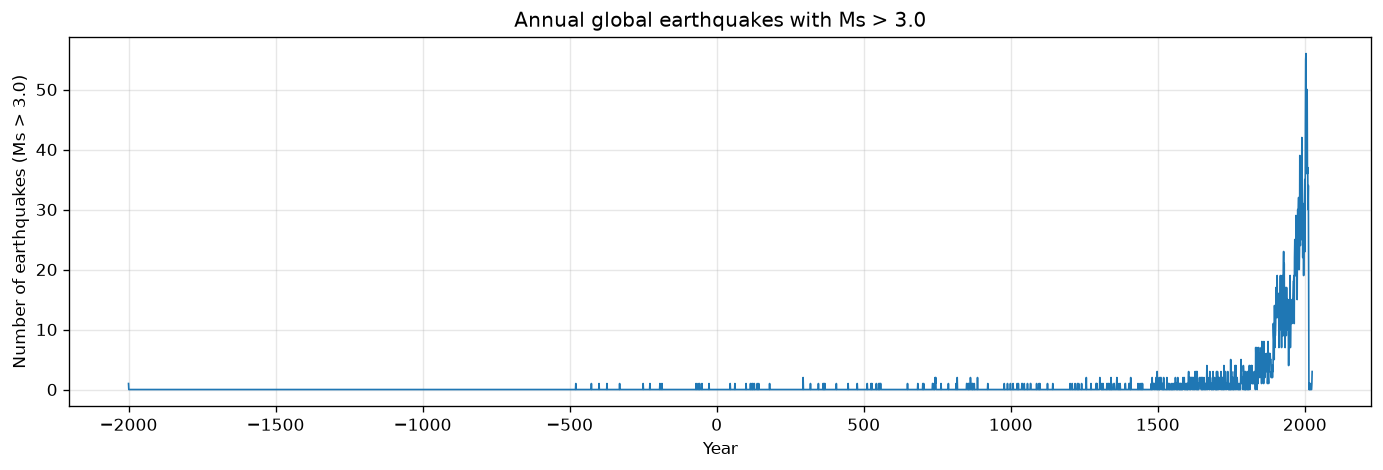


1.2 Linear trend slope = 0.0011 events/year, p-value = 4.272e-97
[报告提示] 频次随时间上升主要与现代地震监测台网完善、记录能力提升有关，不能简单解释为真实地震活动显著增加。

1.3 All countries sorted by total number of earthquakes (FULL OUTPUT):
                                     Country  Total_Earthquakes Largest_Eq_Date                                  Largest_Eq_Location
                                       CHINA                626      1668-07-25                            CHINA:  SHANDONG PROVINCE
                                       JAPAN                429      2011-03-11                                       JAPAN:  HONSHU
                                   INDONESIA                427      2004-12-26          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
                                        IRAN                385       856-12-22                                IRAN:  DAMGHAN, QUMIS
                                      TURKEY                359      1939-12-26                                    TURKEY:  ERZINCAN
        

In [2]:
# =========================================================
# Assignment 02 - 第1题：Significant earthquakes since 2150 B.C.
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120

# 保证完整输出，不折叠行/列
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

path1 = r"D:\huanjingbianceng\2cizuoye\Sig_Eqs.tsv"

# ---------- 数据读取与预处理 ----------
Sig_Eqs = pd.read_csv(path1, sep='\t', dtype=str, low_memory=False)

Sig_Eqs['Id'] = pd.to_numeric(Sig_Eqs['Id'], errors='coerce')
Sig_Eqs = Sig_Eqs.loc[Sig_Eqs['Id'].notna()].copy()

if 'Search Parameters' in Sig_Eqs.columns:
    Sig_Eqs = Sig_Eqs.drop(columns=['Search Parameters'])

num_cols = [
    'Year', 'Mo', 'Dy', 'Deaths', 'Total Deaths',
    'Latitude', 'Longitude', 'Mag', 'Mw', 'Ms', 'Mb', 'Ml', 'Mfa'
]
for c in num_cols:
    if c in Sig_Eqs.columns:
        Sig_Eqs[c] = pd.to_numeric(
            Sig_Eqs[c].astype(str).str.replace(',', '').str.strip(),
            errors='coerce'
        )

Sig_Eqs['Country_clean'] = Sig_Eqs['Country'].astype(str).str.strip()

# 国家名规范化：按你数据中的实际写法继续补充别名
country_alias = {
    'USA': 'UNITED STATES',
    'UNITED STATES OF AMERICA': 'UNITED STATES',
    'U.S.A.': 'UNITED STATES',
    'RUSSIA': 'RUSSIA',
    'RUSSIAN FEDERATION': 'RUSSIA',
    'CHINA': 'CHINA',
    'P.R. CHINA': 'CHINA',
    'PEOPLES REPUBLIC OF CHINA': 'CHINA',
}

def norm_country(x):
    s = str(x).strip()
    if s in ['', '[]', 'nan', 'NAN', 'None']:
        return np.nan
    u = s.upper()
    return country_alias.get(u, u)

Sig_Eqs['Country_norm'] = Sig_Eqs['Country_clean'].map(norm_country)

# 死亡人数：优先 Total Deaths，缺失时用 Deaths
Sig_Eqs['Deaths_use'] = Sig_Eqs['Total Deaths'].fillna(Sig_Eqs['Deaths'])

# ---------- 1.1 死亡人数 Top20 ----------
mask_country = Sig_Eqs['Country_norm'].notna()

country_deaths_top20 = (
    Sig_Eqs.loc[mask_country]
    .groupby('Country_norm')['Deaths_use']
    .sum(min_count=1)
    .sort_values(ascending=False)
    .head(20)
)

print("=" * 70)
print("1.1 Top 20 countries by total earthquake deaths:")
print("=" * 70)
print(country_deaths_top20.to_string())
print("\n[报告提示] 使用了 Total Deaths 优先，缺失时填补 Deaths；"
      "国家名已做大写和别名规范化。")

# ---------- 1.2 Ms > 3.0 地震年频次与趋势 ----------
eq_gt3 = Sig_Eqs.loc[
    Sig_Eqs['Ms'].notna()
    & (Sig_Eqs['Ms'] > 3.0)
    & Sig_Eqs['Year'].notna()
].copy()

yearly_counts = eq_gt3.groupby('Year').size()

# 补齐无地震记录的年份为 0，防止趋势偏倚
full_years = range(int(yearly_counts.index.min()), int(yearly_counts.index.max()) + 1)
yearly_counts = yearly_counts.reindex(full_years, fill_value=0)

plt.figure(figsize=(14, 4))
plt.plot(yearly_counts.index, yearly_counts.values, lw=1)
plt.xlabel('Year')
plt.ylabel('Number of earthquakes (Ms > 3.0)')
plt.title('Annual global earthquakes with Ms > 3.0')
plt.grid(alpha=0.3)
plt.show()

slope, intercept, r, p, se = stats.linregress(
    yearly_counts.index.astype(float),
    yearly_counts.values.astype(float)
)
print("\n" + "=" * 70)
print(f"1.2 Linear trend slope = {slope:.4f} events/year, p-value = {p:.4g}")
print("=" * 70)
print("[报告提示] 频次随时间上升主要与现代地震监测台网完善、记录能力提升有关，"
      "不能简单解释为真实地震活动显著增加。")

# ---------- 1.3 CountEq_LargestEq ----------
def _date_str(row):
    """稳健拼接日期，避免月/日缺失时 int(nan) 报错。"""
    if pd.isna(row['Year']):
        return "Unknown Date"
    y = int(row['Year'])
    if pd.notna(row['Mo']) and pd.notna(row['Dy']):
        return f"{y}-{int(row['Mo']):02d}-{int(row['Dy']):02d}"
    if pd.notna(row['Mo']):
        return f"{y}-{int(row['Mo']):02d}"
    return str(y)

def CountEq_LargestEq(country):
    """
    返回：
    (a) 该国家地震总数
    (b) (最大地震日期, 最大地震位置)
    最大地震按 Mag 列判定；Mag 缺失的记录不参与最大地震判定。
    """
    country_norm = norm_country(country)
    sub = Sig_Eqs.loc[Sig_Eqs['Country_norm'] == country_norm].copy()
    n = len(sub)

    if n == 0:
        return n, (None, None)

    sub_valid = sub.dropna(subset=['Mag', 'Year'])
    if sub_valid.empty:
        loc = sub['Location Name'].iloc[0] if n > 0 else None
        return n, ("Unknown Date", loc)

    # Mag 最大；若相同，取时间最早
    row = sub_valid.sort_values(
        by=['Mag', 'Year', 'Mo', 'Dy'],
        ascending=[False, True, True, True]
    ).iloc[0]

    return n, (_date_str(row), row['Location Name'])

countries = sorted([
    c for c in Sig_Eqs['Country_norm'].dropna().unique()
    if str(c).strip() not in ['', '[]', 'NAN']
])

rows = []
for c in countries:
    n, (date, loc) = CountEq_LargestEq(c)
    rows.append({
        'Country': c,
        'Total_Earthquakes': n,
        'Largest_Eq_Date': date,
        'Largest_Eq_Location': loc
    })

result_1_3 = (
    pd.DataFrame(rows)
    .sort_values('Total_Earthquakes', ascending=False)
    .reset_index(drop=True)
)

# 保存完整结果
result_1_3.to_csv('PS2_1_3_Result.csv', index=False, encoding='utf-8-sig')

# 完整输出所有国家，不截断
print("\n" + "=" * 70)
print("1.3 All countries sorted by total number of earthquakes (FULL OUTPUT):")
print("=" * 70)
print(result_1_3.to_string(index=False))

print("\n完整结果行数:", len(result_1_3))
print("完整统计表已保存到: PS2_1_3_Result.csv")

诊断信息
wx shape: (235674, 54)
DATE 非空: 235674 范围: 1998-01-01 00:00:00 ~ 2022-10-10 23:00:00
TMP 非空原始值: 235674
TMP 前 20 个原始值:
['+0186,1', '+0220,1', '+0240,1', '+0221,1', '+0240,1', '+0240,1', '+0254,1', '+0250,1', '+0250,1', '+0253,1', '+0230,1', '+0220,1', '+0222,1', '+0210,1', '+0200,1', '+0190,1', '+0181,1', '+0175,1', '+0170,1', '+0160,1']
TMP_C 非空: 234877
TMP_QC 分布:
TMP_QC
1.0    234863
9.0       797
2.0        13
5.0         1
Name: count, dtype: int64
过滤后有效行数: 234863
月平均序列长度: 298
有效月平均个数: 298


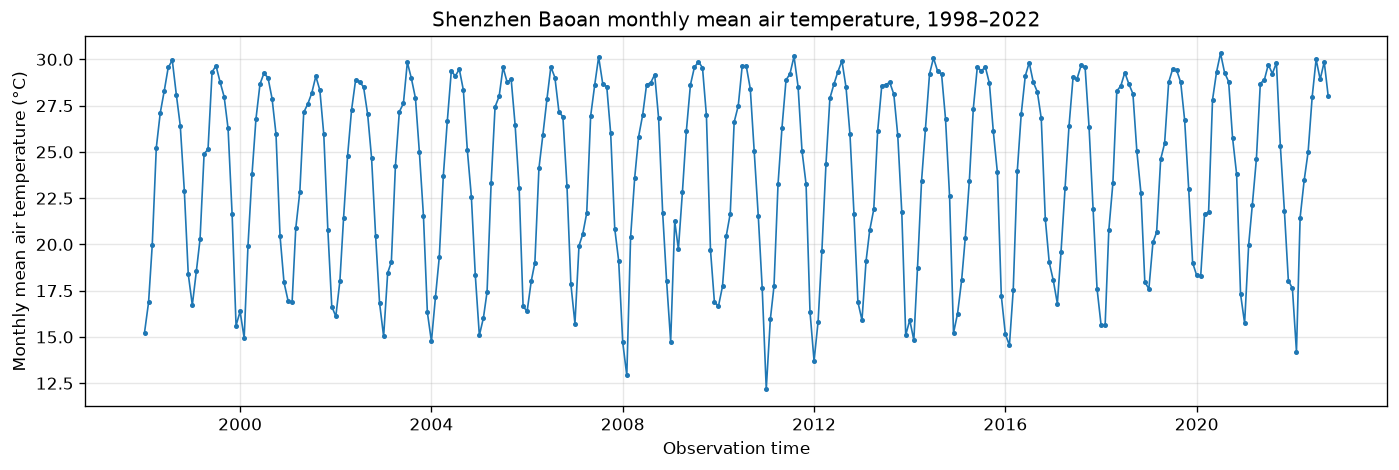

Monthly mean temperature trend = 0.0387 °C/year, p-value = 0.3391, R = 0.056


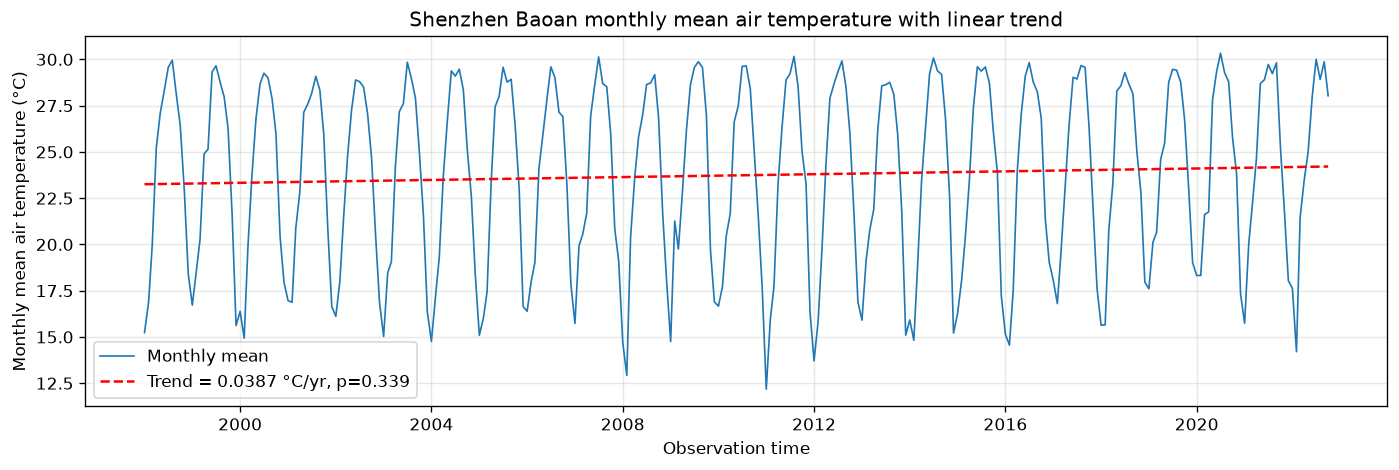

In [3]:
# =========================================================
# Assignment 02 - 第2题：Air temperature in Shenzhen 1998-2022
# =========================================================
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
path2 = r"D:\huanjingbianceng\2cizuoye\Baoan_Weather_1998_2022.csv"

# ---------- 读取 ----------
wx = pd.read_csv(path2, low_memory=False)
wx.columns = wx.columns.str.strip()
wx['DATE'] = pd.to_datetime(wx['DATE'], errors='coerce')

print("=" * 60)
print("诊断信息")
print("=" * 60)
print("wx shape:", wx.shape)
print("DATE 非空:", wx['DATE'].notna().sum(),
      "范围:", wx['DATE'].min(), "~", wx['DATE'].max())
print("TMP 非空原始值:", wx['TMP'].notna().sum())
print("TMP 前 20 个原始值:")
print(wx['TMP'].head(20).tolist())

# ---------- 解析 TMP ----------
def parse_tmp(x):
    """NOAA ISD TMP 格式：+0164,1 -> 16.4 degC, QC=1"""
    if pd.isna(x):
        return np.nan, np.nan
    s = str(x).strip()
    m = re.match(r'^\s*([+-]?\d+)\s*,\s*([0-9]+)\s*$', s)
    if not m:
        return np.nan, np.nan
    val = int(m.group(1)) / 10.0
    qc = int(m.group(2))
    if val >= 999.9:
        return np.nan, qc
    return val, qc

tmp_parsed = wx['TMP'].apply(
    lambda x: pd.Series(parse_tmp(x), index=['TMP_C', 'TMP_QC'])
)
wx = pd.concat([wx, tmp_parsed], axis=1)

print("TMP_C 非空:", wx['TMP_C'].notna().sum())
print("TMP_QC 分布:")
print(wx['TMP_QC'].value_counts(dropna=False).head(10))

# ---------- 过滤 ----------
wx_valid = wx.dropna(subset=['DATE', 'TMP_C']).copy()
wx_valid = wx_valid[wx_valid['TMP_QC'].notna()]

# 只保留 QC 为 0/1 的有效温度记录
wx_valid = wx_valid[wx_valid['TMP_QC'].isin([0, 1])]

# 温度合理范围过滤
wx_valid = wx_valid[(wx_valid['TMP_C'] >= -90) & (wx_valid['TMP_C'] <= 60)]

print("过滤后有效行数:", len(wx_valid))
if len(wx_valid) == 0:
    raise RuntimeError("TMP 过滤后没有有效数据，请检查诊断输出。")

# ---------- 月平均 ----------
monthly_tmp = (
    wx_valid.set_index('DATE')['TMP_C']
    .resample('MS')
    .mean()
)

# 补齐连续月份，保留 NaN，绘图时自然断点，趋势时再 mask
full_months = pd.date_range(
    monthly_tmp.index.min(),
    monthly_tmp.index.max(),
    freq='MS'
)
monthly_tmp = monthly_tmp.reindex(full_months)

print("月平均序列长度:", len(monthly_tmp))
print("有效月平均个数:", monthly_tmp.notna().sum())

plt.figure(figsize=(14, 4))
plt.plot(monthly_tmp.index, monthly_tmp.values, lw=1, marker='o', markersize=2)
plt.xlabel('Observation time')
plt.ylabel('Monthly mean air temperature (°C)')
plt.title('Shenzhen Baoan monthly mean air temperature, 1998–2022')
plt.grid(alpha=0.3)
plt.show()

# ---------- 趋势 ----------
x = monthly_tmp.index.year + (monthly_tmp.index.dayofyear - 1) / 365.25
y = monthly_tmp.values
mask = ~np.isnan(y)

if mask.sum() >= 2:
    slope, intercept, r, p, se = stats.linregress(x[mask], y[mask])
    print(f"Monthly mean temperature trend = {slope:.4f} °C/year, "
          f"p-value = {p:.4g}, R = {r:.3f}")

    plt.figure(figsize=(14, 4))
    plt.plot(monthly_tmp.index, monthly_tmp.values, lw=1, label='Monthly mean')
    plt.plot(monthly_tmp.index, intercept + slope * x, 'r--',
             label=f'Trend = {slope:.4f} °C/yr, p={p:.3g}')
    plt.xlabel('Observation time')
    plt.ylabel('Monthly mean air temperature (°C)')
    plt.title('Shenzhen Baoan monthly mean air temperature with linear trend')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("有效月平均点不足 2 个，无法计算趋势。")

3.1 Top 10 largest hurricanes by maximum WMO_WIND:
                  SID      NAME  SEASON  WMO_WIND
665955  2015293N13266  PATRICIA    2015     185.0
427637  1980214N11330     ALLEN    1980     165.0
605747  2005289N18282     WILMA    2005     160.0
552460  1997253N12255     LINDA    1997     160.0
482075  1988253N12306   GILBERT    1988     160.0
178210  1935241N23291       NaN    1935     160.0
689333  2019236N10314    DORIAN    2019     160.0
629195  2009288N07267      RICK    2009     155.0
560438  1998295N12284     MITCH    1998     155.0
676144  2017242N16333      IRMA    2017     155.0

3.2 WMO_WIND of the 20 strongest-wind hurricanes:
[185.0, 165.0, 160.0, 160.0, 160.0, 160.0, 160.0, 155.0, 155.0, 155.0, 155.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0]

3.3 Datapoint counts by Basin:
BASIN
WP     236576
SI     160668
NaN    124881
SP      67119
EP      62412
NI      55402
SA        119
Name: count, dtype: int64


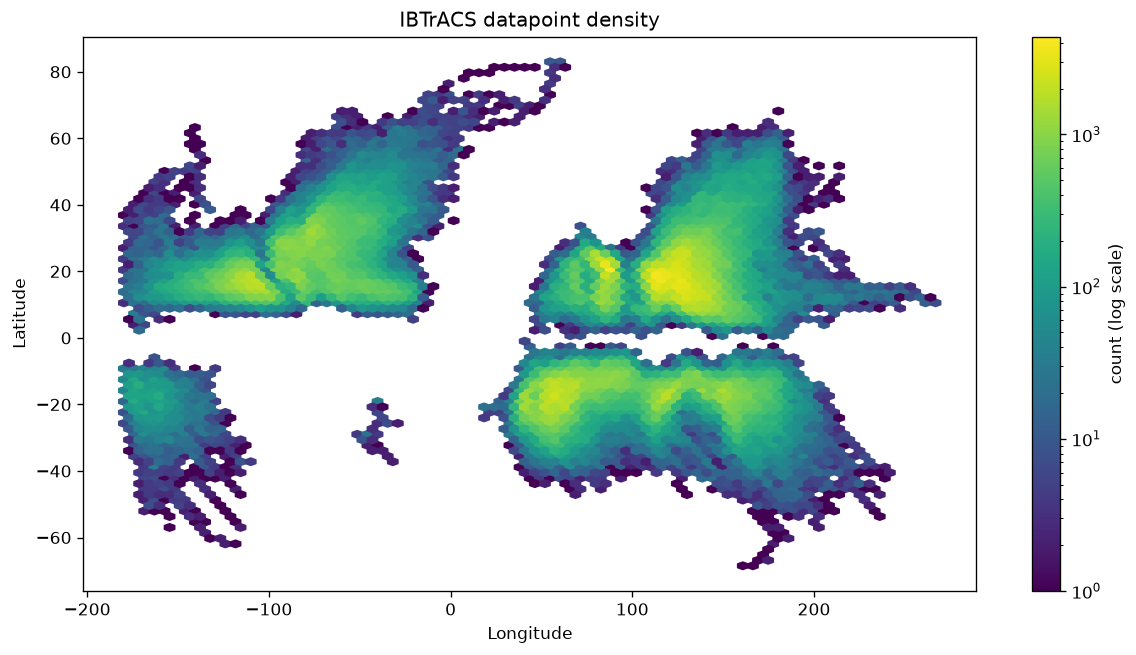

Mangkhut agencies: <ArrowStringArray>
['TOKYO', '']
Length: 2, dtype: str

3.5 Typhoon Mangkhut (2018) records:
                  SID      NAME            ISO_TIME     LAT      LON  WMO_WIND
683027  2018250N12170  MANGKHUT 2018-09-07 12:00:00  12.820  165.367      35.0
683029  2018250N12170  MANGKHUT 2018-09-07 18:00:00  13.075  163.800      35.0
683031  2018250N12170  MANGKHUT 2018-09-08 00:00:00  13.600  162.350      40.0
683033  2018250N12170  MANGKHUT 2018-09-08 06:00:00  14.300  160.825      40.0
683035  2018250N12170  MANGKHUT 2018-09-08 12:00:00  14.575  159.125      45.0
683037  2018250N12170  MANGKHUT 2018-09-08 18:00:00  14.750  157.125      50.0
683039  2018250N12170  MANGKHUT 2018-09-09 00:00:00  14.925  155.050      65.0
683041  2018250N12170  MANGKHUT 2018-09-09 06:00:00  15.300  153.025      65.0
683043  2018250N12170  MANGKHUT 2018-09-09 12:00:00  15.150  151.225      70.0
683045  2018250N12170  MANGKHUT 2018-09-09 18:00:00  14.650  149.125      80.0
683047  2018250N121

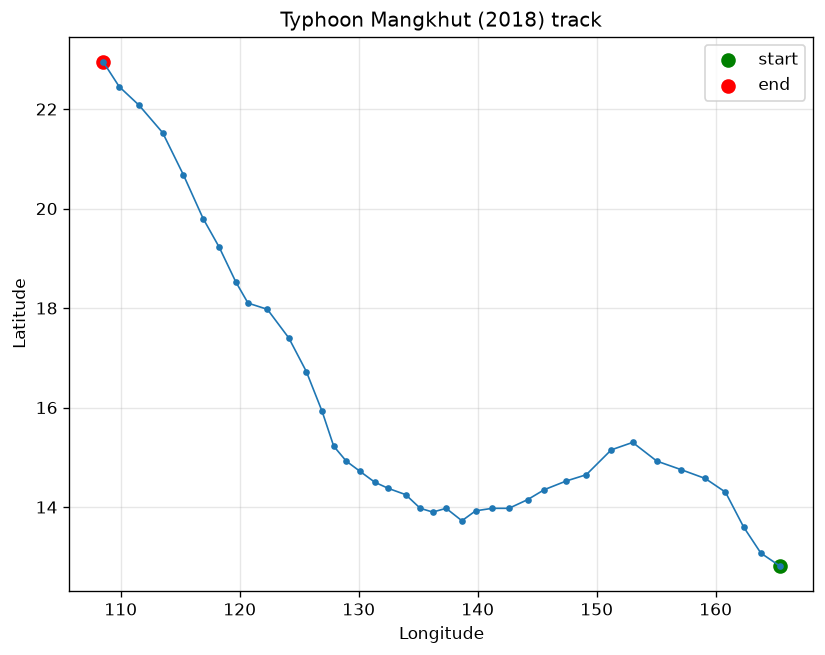

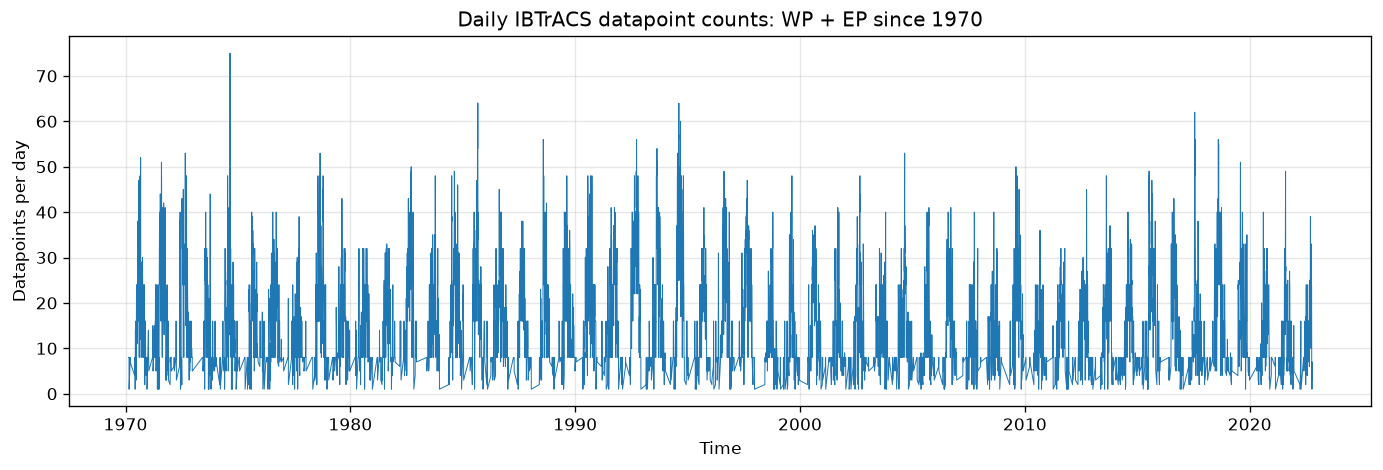

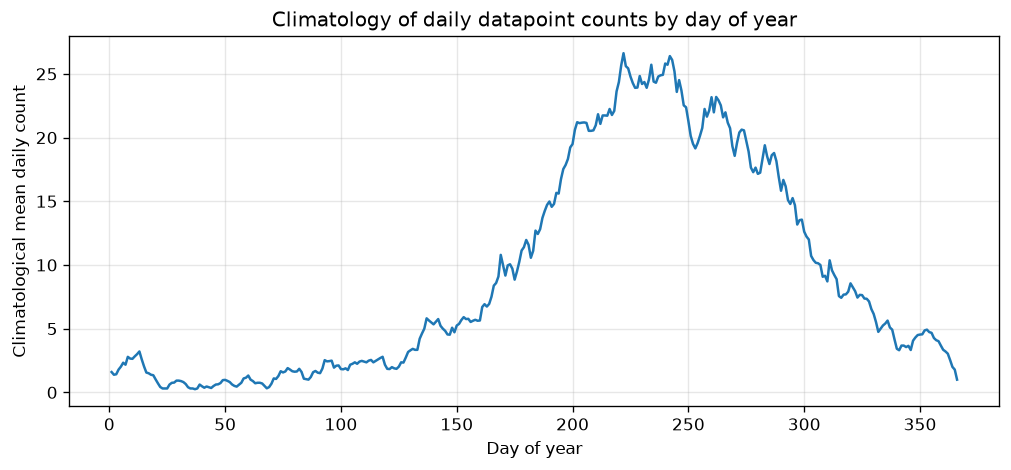

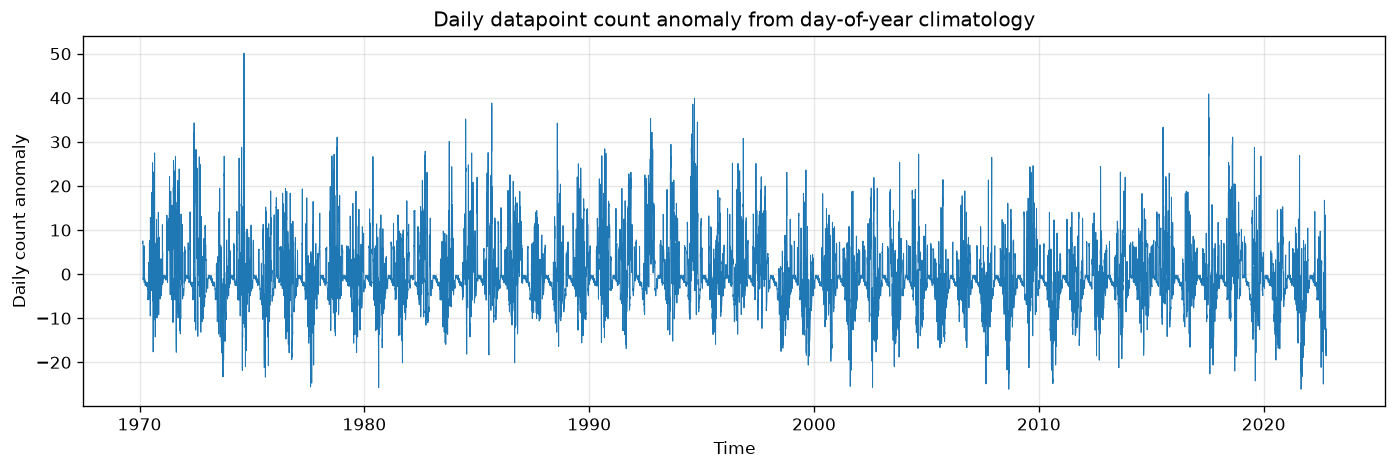

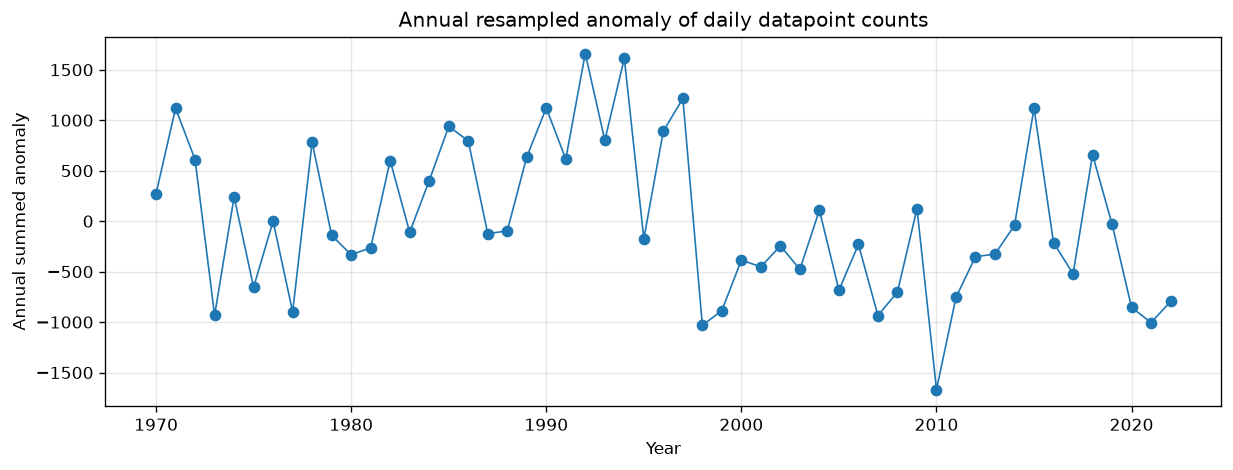

Years with highest annual summed anomaly:
1992-01-01    1660.725327
1994-01-01    1611.725327
1997-01-01    1215.725327
1990-01-01    1121.725327
2015-01-01    1119.725327
1971-01-01    1118.725327
1985-01-01     938.725327
1996-01-01     890.725327
1993-01-01     800.725327
1986-01-01     795.725327
Name: anomaly, dtype: float64

Years with lowest annual summed anomaly:
2010-01-01   -1668.274673
1998-01-01   -1033.274673
2021-01-01   -1004.274673
2007-01-01    -935.274673
1973-01-01    -933.274673
1977-01-01    -899.274673
1999-01-01    -885.274673
2020-01-01    -855.274673
2022-01-01    -796.063135
2011-01-01    -755.274673
Name: anomaly, dtype: float64


In [4]:
# =========================================================
# Assignment 02 - 第3题：Global collection of hurricanes
# =========================================================
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
path3 = r"D:\huanjingbianceng\2cizuoye\ibtracs.ALL.list.v04r00.csv"

# ---------- 读取 ----------
# IBTrACS 常见格式：第1行列名，第2行单位，第3行开始数据
# 所以只跳过第2行单位行；如果文件结构不同，请先检查前3行。
df = pd.read_csv(
    path3,
    usecols=range(17),
    skiprows=[1],
    parse_dates=['ISO_TIME'],
    na_values=['NOT_NAMED', ''],
    low_memory=False
)

def parse_latlon(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.number)):
        return float(x)
    s = str(x).strip().upper()
    if s in ['', 'NAN']:
        return np.nan
    try:
        return float(s)
    except ValueError:
        pass
    m = re.match(r'^([+-]?\d+(?:\.\d+)?)\s*([NSEW])$', s)
    if not m:
        return np.nan
    val = float(m.group(1))
    hemi = m.group(2)
    if hemi in ['S', 'W']:
        val = -abs(val)
    return val

df['LAT'] = df['LAT'].apply(parse_latlon)
df['LON'] = df['LON'].apply(parse_latlon)
df['WMO_WIND'] = pd.to_numeric(df['WMO_WIND'], errors='coerce')
df['SEASON'] = pd.to_numeric(df['SEASON'], errors='coerce')
df['NAME'] = (
    df['NAME']
    .astype(str)
    .str.strip()
    .str.upper()
    .replace({'NAN': np.nan, '': np.nan})
)

# ---------- 3.1 ----------
valid_wind = df.dropna(subset=['SID', 'WMO_WIND']).copy()
idx = valid_wind.groupby('SID')['WMO_WIND'].idxmax()
storm_max = valid_wind.loc[idx].copy()

top10_storms = (
    storm_max.sort_values('WMO_WIND', ascending=False)
    .head(10)[['SID', 'NAME', 'SEASON', 'WMO_WIND']]
)
print("3.1 Top 10 largest hurricanes by maximum WMO_WIND:")
print(top10_storms)

# ---------- 3.2 ----------
top20_wind = (
    storm_max.sort_values('WMO_WIND', ascending=False)
    .head(20)['WMO_WIND'].tolist()
)
print("\n3.2 WMO_WIND of the 20 strongest-wind hurricanes:")
print(top20_wind)

# ---------- 3.3 ----------
basin_counts = df['BASIN'].value_counts(dropna=False)
print("\n3.3 Datapoint counts by Basin:")
print(basin_counts)

# ---------- 3.4 ----------
hex_df = df.dropna(subset=['LAT', 'LON']).copy()
hex_df = hex_df[
    hex_df['LAT'].between(-90, 90)
    & hex_df['LON'].between(-180, 360)
]

plt.figure(figsize=(12, 6))
plt.hexbin(
    hex_df['LON'], hex_df['LAT'],
    gridsize=80, mincnt=1, cmap='viridis',
    norm=LogNorm(vmin=1)
)
plt.colorbar(label='count (log scale)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('IBTrACS datapoint density')
plt.show()

# ---------- 3.5 ----------
mang = df[(df['NAME'] == 'MANGKHUT') & (df['SEASON'] == 2018)].copy()

if 'WMO_AGENCY' in mang.columns:
    mang['WMO_AGENCY_clean'] = (
        mang['WMO_AGENCY'].astype(str).str.strip().str.upper()
    )
    print("Mangkhut agencies:", mang['WMO_AGENCY_clean'].unique())

    # 优先保留有 WMO_WIND 的官方记录；没有则保留全部
    mang_wmo = mang[mang['WMO_WIND'].notna()].copy()
    if len(mang_wmo) > 0:
        mang = mang_wmo

mang = mang.sort_values('ISO_TIME').drop_duplicates('ISO_TIME')

print("\n3.5 Typhoon Mangkhut (2018) records:")
print(mang[['SID', 'NAME', 'ISO_TIME', 'LAT', 'LON', 'WMO_WIND']])

if len(mang) > 0:
    plt.figure(figsize=(8, 6))
    plt.plot(mang['LON'], mang['LAT'], '-o', markersize=3, lw=1)
    plt.scatter(mang['LON'].iloc[0], mang['LAT'].iloc[0],
                c='green', s=60, label='start')
    plt.scatter(mang['LON'].iloc[-1], mang['LAT'].iloc[-1],
                c='red', s=60, label='end')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Typhoon Mangkhut (2018) track')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("No Mangkhut 2018 records found. Check NAME/SEASON parsing.")

# ---------- 3.6 ----------
filtered = df[
    (df['SEASON'] >= 1970)
    & (df['BASIN'].isin(['WP', 'EP']))
].copy()
filtered = filtered.dropna(subset=['ISO_TIME'])

# ---------- 3.7 ----------
daily_counts = (
    filtered.groupby(filtered['ISO_TIME'].dt.normalize())
    .size()
    .sort_index()
)

plt.figure(figsize=(14, 4))
plt.plot(daily_counts.index, daily_counts.values, lw=0.6)
plt.xlabel('Time')
plt.ylabel('Datapoints per day')
plt.title('Daily IBTrACS datapoint counts: WP + EP since 1970')
plt.grid(alpha=0.3)
plt.show()

# ---------- 3.8 ----------
daily_df = daily_counts.to_frame('count')
full_dates = pd.date_range(
    daily_df.index.min(),
    daily_df.index.max(),
    freq='D'
)
daily_df = daily_df.reindex(full_dates)
daily_df['count'] = daily_df['count'].fillna(0)

daily_df['doy'] = daily_df.index.dayofyear
clim = daily_df.groupby('doy')['count'].mean()

plt.figure(figsize=(10, 4))
plt.plot(clim.index, clim.values, lw=1.5)
plt.xlabel('Day of year')
plt.ylabel('Climatological mean daily count')
plt.title('Climatology of daily datapoint counts by day of year')
plt.grid(alpha=0.3)
plt.show()

# ---------- 3.9 ----------
daily_df['clim'] = daily_df['doy'].map(clim).fillna(0)
daily_df['anomaly'] = daily_df['count'] - daily_df['clim']

plt.figure(figsize=(14, 4))
plt.plot(daily_df.index, daily_df['anomaly'].values, lw=0.6)
plt.xlabel('Time')
plt.ylabel('Daily count anomaly')
plt.title('Daily datapoint count anomaly from day-of-year climatology')
plt.grid(alpha=0.3)
plt.show()

# ---------- 3.10 ----------
try:
    annual_anom = daily_df['anomaly'].resample('YS').sum()
except ValueError:
    annual_anom = daily_df['anomaly'].resample('AS').sum()

plt.figure(figsize=(12, 4))
plt.plot(annual_anom.index, annual_anom.values, marker='o', lw=1)
plt.xlabel('Year')
plt.ylabel('Annual summed anomaly')
plt.title('Annual resampled anomaly of daily datapoint counts')
plt.grid(alpha=0.3)
plt.show()

print("Years with highest annual summed anomaly:")
print(annual_anom.sort_values(ascending=False).head(10))
print("\nYears with lowest annual summed anomaly:")
print(annual_anom.sort_values().head(10))

Columns in USW00014842.csv:
['STATION', 'DATE', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'NAME', 'PRCP', 'PRCP_ATTRIBUTES', 'SNOW', 'SNOW_ATTRIBUTES', 'SNWD', 'SNWD_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN', 'TMIN_ATTRIBUTES', 'ACMH', 'ACMH_ATTRIBUTES', 'ACSH', 'ACSH_ATTRIBUTES', 'ADPT', 'ADPT_ATTRIBUTES', 'ASLP', 'ASLP_ATTRIBUTES', 'ASTP', 'ASTP_ATTRIBUTES', 'AWBT', 'AWBT_ATTRIBUTES', 'AWND', 'AWND_ATTRIBUTES', 'FMTM', 'FMTM_ATTRIBUTES', 'FRGB', 'FRGB_ATTRIBUTES', 'FRGT', 'FRGT_ATTRIBUTES', 'FRTH', 'FRTH_ATTRIBUTES', 'GAHT', 'GAHT_ATTRIBUTES', 'PGTM', 'PGTM_ATTRIBUTES', 'PSUN', 'PSUN_ATTRIBUTES', 'RHAV', 'RHAV_ATTRIBUTES', 'RHMN', 'RHMN_ATTRIBUTES', 'RHMX', 'RHMX_ATTRIBUTES', 'TAVG', 'TAVG_ATTRIBUTES', 'TSUN', 'TSUN_ATTRIBUTES', 'WDF1', 'WDF1_ATTRIBUTES', 'WDF2', 'WDF2_ATTRIBUTES', 'WDF5', 'WDF5_ATTRIBUTES', 'WDFG', 'WDFG_ATTRIBUTES', 'WDFM', 'WDFM_ATTRIBUTES', 'WESD', 'WESD_ATTRIBUTES', 'WSF1', 'WSF1_ATTRIBUTES', 'WSF2', 'WSF2_ATTRIBUTES', 'WSF5', 'WSF5_ATTRIBUTES', 'WSFG', 'WSFG_A

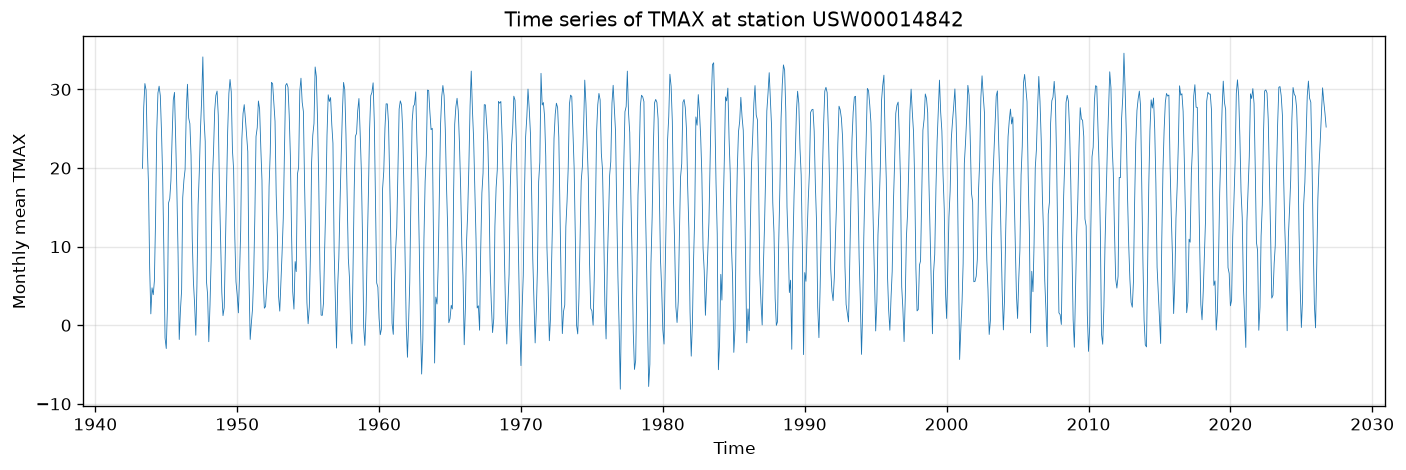


===== 4.3 Statistical checks =====
1) Missing rate of TMAX: 0.01%
2) Descriptive statistics of cleaned TMAX:
count    30475.000000
mean        16.346661
std         12.034546
min        -23.900000
25%          6.100000
50%         17.800000
75%         26.700000
max         40.600000
Name: TMAX, dtype: float64
3) Number of IQR outliers: 0
Empty DataFrame
Columns: [DATE, TMAX]
Index: []
4) Monthly climatology of TMAX:
month
1     -0.031753
2      2.720102
3      9.608239
4     16.932570
5     22.829450
6     27.985624
7     29.830184
8     28.834524
9     25.210794
10    18.499033
11     9.757912
12     2.608589
Name: TMAX, dtype: float64


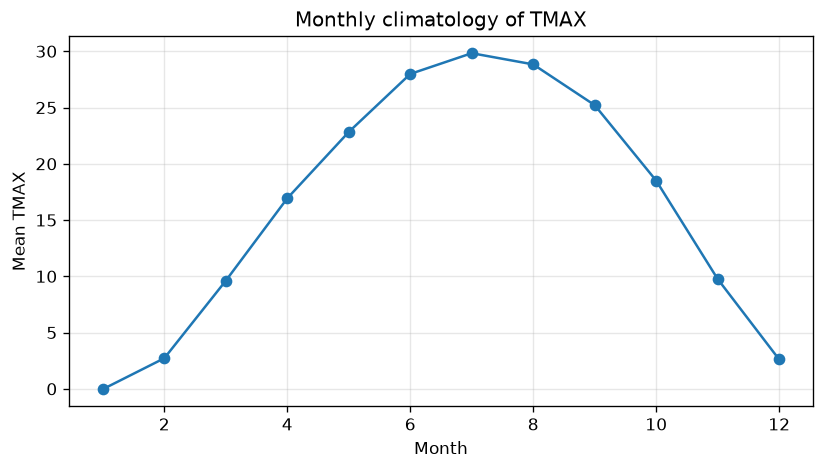

5) Linear trend of TMAX: slope=0.02049 per year, p-value=7.961e-13, R=0.041
6) Lag-1 autocorrelation of TMAX: 0.926
7) Skewness=-0.388, Kurtosis=-0.863


In [1]:
# =========================================================
# Assignment 02 - 第4题：Explore a data set (USW00014842.csv)
# =========================================================
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
path4 = r"D:\huanjingbianceng\2cizuoye\USW00014842.csv"

# ---------- 4.1 读取 ----------
def _read_ncei(path):
    for skip in [0, 1, 2, 3]:
        try:
            d = pd.read_csv(path, skiprows=skip, low_memory=False)
            if d.shape[1] >= 3 and len(d.columns) > 1:
                return d
        except Exception:
            continue
    raise RuntimeError(f"Cannot parse {path}, please inspect the file header manually.")

data4 = _read_ncei(path4)
print("Columns in USW00014842.csv:")
print(data4.columns.tolist())
print(data4.head())

# 自动识别日期列
date_col = None
for c in data4.columns:
    if c.upper() in ['DATE', 'DATETIME', 'DATE_TIME', 'TIMESTAMP', 'TIME', 'DATE_LOCAL']:
        date_col = c
        break
if date_col is None:
    raise ValueError("未找到日期列，请手动指定 date_col。")
data4[date_col] = pd.to_datetime(data4[date_col], errors='coerce')

# 优先选择常见变量
preferred_vars = ['TMAX', 'TMIN', 'TMP', 'PRCP', 'AWND', 'WSF2', 'SNOW', 'SNWD', 'TOBS']
var = next((c for c in preferred_vars if c in data4.columns), None)
if var is None:
    numeric_cols = [
        c for c in data4.select_dtypes(include=[np.number]).columns
        if c != date_col
    ]
    if len(numeric_cols) == 0:
        raise ValueError("未找到可用数值变量，请手动指定 var。")
    var = numeric_cols[0]

print(f"Chosen date column: {date_col}")
print(f"Chosen variable: {var}")

def parse_tmp(x):
    if pd.isna(x):
        return np.nan, np.nan
    s = str(x).strip()
    m = re.match(r'^\s*([+-]?\d+)\s*,\s*([0-9])\s*$', s)
    if not m:
        return np.nan, np.nan
    val = int(m.group(1)) / 10.0
    qc  = int(m.group(2))
    if val >= 999.9:
        return np.nan, qc
    return val, qc

# 清洗变量
if data4[var].dtype == object and data4[var].astype(str).str.contains(',').any():
    parsed = data4[var].apply(
        lambda x: pd.Series(parse_tmp(x), index=[var+'_v', var+'_qc'])
    )
    data4[var]        = parsed[var+'_v']
    data4[var+'_qc']  = parsed[var+'_qc']
    data4 = data4[~data4[var+'_qc'].isin([2, 9])]
    print(f"{var} parsed from ISD comma format.")
else:
    data4[var] = pd.to_numeric(data4[var], errors='coerce')
    data4.loc[data4[var] < -9000, var] = np.nan
    if var in ['TMAX', 'TMIN', 'TOBS'] and data4[var].abs().median() > 100:
        data4[var] = data4[var] / 10.0
        print(f"{var} converted from tenths of °C to °C.")

# QC 过滤：GHCN-Daily 常见 QFLAG，保留空值/无 flag 记录
for qc_col in ['QFLAG', 'QFLAG2', 'QUALITY_CONTROL', 'QLAG']:
    if qc_col in data4.columns:
        print(f"Found QC column: {qc_col}")
        data4 = data4[data4[qc_col].isna() | (data4[qc_col].astype(str).str.strip() == '')]
        print(f"After QC filter: {len(data4)} rows remain")
        break

clean4 = data4.dropna(subset=[date_col, var]).sort_values(date_col).copy()

# ---------- 4.2 时间序列 ----------
if len(clean4) > 5000:
    plot_series = clean4.set_index(date_col)[var].resample('MS').mean()
    ylabel = f"Monthly mean {var}"
else:
    plot_series = clean4.set_index(date_col)[var]
    ylabel = var

plt.figure(figsize=(14, 4))
plt.plot(plot_series.index, plot_series.values, lw=0.5)
plt.xlabel('Time')
plt.ylabel(ylabel)
plt.title(f'Time series of {var} at station USW00014842')
plt.grid(alpha=0.3)
plt.show()

# ---------- 4.3 至少5个统计检查 ----------
print("\n===== 4.3 Statistical checks =====")

# Check 1: 缺失率
missing_rate = data4[var].isna().mean()
print(f"1) Missing rate of {var}: {missing_rate:.2%}")

# Check 2: 描述性统计
print(f"2) Descriptive statistics of cleaned {var}:")
print(clean4[var].describe())

# Check 3: IQR 异常值
q1, q3 = clean4[var].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = clean4[
    (clean4[var] < q1 - 1.5 * iqr)
    | (clean4[var] > q3 + 1.5 * iqr)
]
print(f"3) Number of IQR outliers: {len(outliers)}")
print(outliers[[date_col, var]].head())

# Check 4: 月气候态
clean4['month'] = clean4[date_col].dt.month
monthly_clim_4 = clean4.groupby('month')[var].mean()
print(f"4) Monthly climatology of {var}:")
print(monthly_clim_4)

plt.figure(figsize=(8, 4))
plt.plot(monthly_clim_4.index, monthly_clim_4.values, marker='o')
plt.xlabel('Month')
plt.ylabel(f'Mean {var}')
plt.title(f'Monthly climatology of {var}')
plt.grid(alpha=0.3)
plt.show()

# Check 5: 线性趋势
x4 = (clean4[date_col] - clean4[date_col].min()).dt.days / 365.25
y4 = clean4[var]
mask4 = y4.notna()
slope4, intercept4, r4, p4, se4 = stats.linregress(x4[mask4], y4[mask4])
print(f"5) Linear trend of {var}: slope={slope4:.5f} per year, p-value={p4:.4g}, R={r4:.3f}")

# Check 6: lag-1 自相关
ac1 = clean4[var].dropna().autocorr(lag=1)
print(f"6) Lag-1 autocorrelation of {var}: {ac1:.3f}")

# Check 7: 偏度/峰度
print(f"7) Skewness={clean4[var].skew():.3f}, Kurtosis={clean4[var].kurtosis():.3f}")